# TSII - Project Modelation and Simulation of Systems - Rocket

### Members
| Name | Carnet |
|---|---|
| Jose Iván Barreno Bulux   | 22003949 |
| Luis Fernando Guzmán Orozco | 21000542 |
| Byron Haldaír García Guzmán | 22003366 |
| José Javier Rivera Cruz | 18007794 |

In [65]:
%matplotlib inline
import numpy as np
import scipy.signal as signal
import scipy.linalg as la
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import display, Math

# Enable MathJax LaTeX formatting in Jupyter
sp.init_printing(use_latex='mathjax')

In [66]:
def define_mimo_system(A_in, B_in, C_in=None, D_in=None):
    """
    Module 1: Define and validate matrices for a continuous-time LTI MIMO system.
    Mathematical Function: Creates StateSpace object sys = signal.StateSpace(A, B, C, D).
    """
    A_num = np.array(A_in, dtype=float)
    B_num = np.array(B_in, dtype=float)
    
    # Validations to ensure that the matrices have the right shape
    n = A_num.shape[0]
    if A_num.shape[1] != n:
        raise ValueError(f"Matrix A must be square. Given dimensions: {A_num.shape}")
    if B_num.shape[0] != n:
        raise ValueError(f"Matrix B rows must match A ({n}). Given dimensions: {B_num.shape}")
    r = B_num.shape[1]
    
    if C_in is None:
        C_num = np.eye(n)
        m = n
    else:
        C_num = np.array(C_in, dtype=float)
        if C_num.shape[1] != n:
            raise ValueError(f"Matrix C must have {n} columns. Given: {C_num.shape}")
        m = C_num.shape[0]
        
    if D_in is None:
        D_num = np.zeros((m, r))
    else:
        D_num = np.array(D_in, dtype=float)
        if D_num.shape != (m, r):
            raise ValueError(f"Matrix D must be of size {m}x{r}. Given: {D_num.shape}")
            
    # Create StateSpace system object with SciPy LTI
    sys = signal.StateSpace(A_num, B_num, C_num, D_num)
    
    # SymPy matrix representation for clean LaTeX rendering
    A_sp, B_sp, C_sp, D_sp = sp.Matrix(A_in), sp.Matrix(B_in), sp.Matrix(C_in), sp.Matrix(D_in)
    
    display(Math(r"\text{--- Module 1: MIMO State-Space Setup ---}"))
    display(Math(rf"\dot{{x}}(t) = {sp.latex(A_sp)} x(t) + {sp.latex(B_sp)} u(t)"))
    display(Math(rf"y(t) = {sp.latex(C_sp)} x(t) + {sp.latex(D_sp)} u(t)"))
    
    return sys, A_num, B_num, C_num, D_num, A_sp, B_sp, C_sp, D_sp

In [67]:
def compute_transfer_matrix(A_sp, B_sp, C_sp, D_sp, A_num, B_num, C_num, D_num):
    """
    Module 2: Compute Transfer Function Matrix G(p) and System Poles.
    Mathematical Function: Resolvent matrix (pI - A)^-1 and poles via np.linalg.eigvals(A).
    """
    p = sp.symbols('p')
    n = A_sp.rows
    
    characteristic_matrix = p * sp.eye(n) - A_sp
    characteristic_poly = sp.expand(characteristic_matrix.det())
    
    # Compute Transfer Functions using scipy.signal.ss2tf for guaranteed speed
    m_out, r_in = C_num.shape[0], B_num.shape[1]
    tf_matrix_sp = sp.zeros(m_out, r_in)
    for i in range(m_out):
        for j in range(r_in):
            num, den = signal.ss2tf(A_num, B_num[:, [j]], C_num[[i], :], D_num[[i], [j]])
            num_poly = sum(sp.Rational(float(c)).limit_denominator(1000000) * p**(len(num[0])-1-k) for k, c in enumerate(num[0]) if abs(c) > 1e-12)
            den_poly = sum(sp.Rational(float(c)).limit_denominator(1000000) * p**(len(den)-1-k) for k, c in enumerate(den) if abs(c) > 1e-12)
            tf_matrix_sp[i, j] = num_poly / den_poly if den_poly != 0 else 0
            
    # Numeric poles via numpy.linalg.eigvals
    poles_num = np.linalg.eigvals(A_num)
    
    display(Math(r"\text{--- Module 2: Transfer Function Matrix G(p) ---}"))
    display(Math(rf"\det(pI - A) = {sp.latex(characteristic_poly)}"))
    display(Math(rf"G(p) = C(pI - A)^{{-1}}B + D = {sp.latex(tf_matrix_sp)}"))
    display(Math(rf"\text{{System Poles: }} {sp.latex([round(float(np.real(val)), 6) + round(float(np.imag(val)), 6)*1j for val in poles_num])}"))
    
    return tf_matrix_sp, poles_num

In [68]:
def compute_transition_matrix(A_sp, A_num):
    """
    Module 3: Transition Matrix Phi(t) = exp(A*t).
    Mathematical Function: Fast numerical evaluation via scipy.linalg.expm(A * t).
    """
    t = sp.symbols('t', real=True)
    
    display(Math(r"\text{--- Module 3: Transition Matrix \Phi(t) ---}"))
    display(Math(r"\Phi(t) = e^{At} = \mathcal{L}^{-1}\{(pI - A)^{-1}\}"))
    
    # Numerical evaluation helper function
    def phi_numeric(t_val):
        return la.expm(A_num * t_val)
        
    # Display Phi(t) evaluated at representative t = 1.0 min
    Phi_sample = sp.Matrix(np.round(phi_numeric(1.0), 6))
    display(Math(rf"\Phi(t=1.0) = e^{{A \cdot 1.0}} = {sp.latex(Phi_sample)}"))
    
    # Sanity check: Phi(0) = I
    check_zero = np.allclose(phi_numeric(0), np.eye(A_num.shape[0]))
    display(Math(rf"\text{{Verification: }} \Phi(0) = I \Rightarrow \texttt{{{check_zero}}}"))
    
    return phi_numeric

In [69]:
def plot_dynamic_responses(sys, title_suffix="", T_max=100, K_dose=1.0, pulse_width=2.0):
    """
    Module 4: Dynamic Time-Domain Responses using scipy.signal functions.
    Calculates impulse response (signal.impulse), step response (signal.step), and forced pulse response (signal.lsim).
    Provides BOTH combined overview plots and individual state/output subplots.
    """
    # 1. Impulse Response: signal.impulse
    t_imp, y_imp = signal.impulse(sys, T=np.linspace(0, T_max, 1000))
    y_imp = y_imp * K_dose  # Scale by dose K
    
    # 2. Step Response: signal.step
    t_step, y_step = signal.step(sys, T=np.linspace(0, T_max, 1000))
    
    # 3. Forced Pulse Response: signal.lsim
    T_sim = np.linspace(0, T_max, 1000)
    U_sim = np.where((T_sim >= 0) & (T_sim <= pulse_width), K_dose / pulse_width, 0.0)
    t_pulse, y_pulse, x_pulse = signal.lsim(sys, U_sim, T_sim)
    
    n_states = sys.C.shape[0]
    state_labels = [f"x{i+1}" for i in range(n_states)]
    
    # --- COMBINED PLOTS OVERVIEW ---
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    
    # Impulse
    for i in range(n_states):
        axs[0].plot(t_imp, y_imp[:, i], label=state_labels[i])
    axs[0].set_title(f"Impulse Response {title_suffix}")
    axs[0].set_xlabel("Time [min]")
    axs[0].set_ylabel("Amount / Concentration")
    axs[0].grid(True, linestyle='--', alpha=0.6)
    axs[0].legend()
    
    # Step
    for i in range(n_states):
        axs[1].plot(t_step, y_step[:, i], label=state_labels[i])
    axs[1].set_title(f"Step Response {title_suffix}")
    axs[1].set_xlabel("Time [min]")
    axs[1].set_ylabel("Amount / Concentration")
    axs[1].grid(True, linestyle='--', alpha=0.6)
    axs[1].legend()
    
    # Pulse (Realistic Injection)
    for i in range(n_states):
        axs[2].plot(t_pulse, y_pulse[:, i], label=state_labels[i])
    axs[2].set_title(f"Pulse Infusion (2 min) {title_suffix}")
    axs[2].set_xlabel("Time [min]")
    axs[2].set_ylabel("Amount / Concentration")
    axs[2].grid(True, linestyle='--', alpha=0.6)
    axs[2].legend()
    
    plt.tight_layout()
    plt.show()
    
    # --- INDIVIDUAL SUBPLOTS OPTION ---
    fig_ind, axs_ind = plt.subplots(n_states, 1, figsize=(10, 2.5 * n_states), sharex=True)
    for i in range(n_states):
        axs_ind[i].plot(t_imp, y_imp[:, i], label=f"{state_labels[i]} (Impulse)", color='crimson')
        axs_ind[i].plot(t_pulse, y_pulse[:, i], label=f"{state_labels[i]} (Pulse)", color='darkblue', linestyle='--')
        axs_ind[i].set_ylabel(state_labels[i])
        axs_ind[i].grid(True, linestyle=':', alpha=0.6)
        axs_ind[i].legend(loc='upper right')
    axs_ind[-1].set_xlabel("Time [min]")
    fig_ind.suptitle(f"Individual State Trajectories {title_suffix}", y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

In [70]:
def plot_time_response(sys, T_max=5.0, num_pts=2000, inputs=("impulse", "step"),
                       title_suffix="", xlabel="Time [s]", ylabel="Output y(t)"):
    """
    Reusable time-domain plot for any StateSpace system (SISO or MIMO).
    One subplot per input type; each curve is one output (channel) of the system.
    inputs: any of "impulse", "step". Uses signal.impulse / signal.step.
    Returns {name: (t, y)} with y shaped (len(t), n_outputs).
    """
    T = np.linspace(0, T_max, num_pts)
    solvers = {"impulse": signal.impulse, "step": signal.step}
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    n_out = sys.C.shape[0]

    fig, axs = plt.subplots(1, len(inputs), figsize=(7 * len(inputs), 4.5), squeeze=False)
    results = {}
    for ax, name in zip(axs[0], inputs):
        t, y = solvers[name](sys, T=T)
        y = np.asarray(y).reshape(len(t), n_out)   # SISO returns 1D -> force 2D
        results[name] = (t, y)
        for i in range(n_out):
            ax.plot(t, y[:, i], color=colors[i % len(colors)], label=f"y{i+1}")
        ax.axhline(0, color='k', lw=0.5)
        ax.set_title(f"{name.capitalize()} response {title_suffix}")
        ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
        ax.grid(True, ls='--', alpha=0.6)
        if n_out > 1: ax.legend()
    plt.tight_layout(); plt.show()
    return results

In [71]:
def plot_sinusoidal_response(sys, omegas, n_periods=8, num_pts=2000, title_suffix="",
                             input_idx=0, output_idx=0):
    """
    Reusable: forced response to u(t)=sin(w t) for several frequencies using signal.lsim.
    Gain |G(jw)| comes from signal.freqresp; reports it next to the measured steady-state amplitude.
    """
    sys_siso = signal.StateSpace(sys.A, sys.B[:, [input_idx]], sys.C[[output_idx], :], sys.D[[output_idx], [input_idx]])
    fig, axs = plt.subplots(len(omegas), 1, figsize=(10, 2.8 * len(omegas)))
    axs = np.atleast_1d(axs)
    out = {}
    for ax, w in zip(axs, omegas):
        T = np.linspace(0, n_periods * 2 * np.pi / w, num_pts)
        u = np.sin(w * T)
        _, y, _ = signal.lsim(sys_siso, u, T)
        _, H = signal.freqresp(sys_siso, w=[w])
        gain = np.abs(H[0])
        meas = np.max(np.abs(y[len(y)//2:]))      # steady-state amplitude (2nd half)
        out[w] = (gain, meas)
        ax.plot(T, u, 'k--', alpha=0.6, label="u(t) camino")
        ax.plot(T, y, color='crimson', label="y(t) cuadro")
        ax.set_title(rf"$\omega$ = {w:.3g} rad/s | |G| = {gain:.3f} ({20*np.log10(gain):.1f} dB) | amplitud medida = {meas:.3f}")
        ax.set_xlabel("Tiempo [s]"); ax.grid(True, ls='--', alpha=0.6); ax.legend(loc='upper right')
    fig.suptitle(f"Sinusoidal response {title_suffix}", y=1.01)
    plt.tight_layout(); plt.show()
    return out

In [72]:
def check_system_properties(A_num, B_num, C_num):
    """
    Module 5: System Properties - Stability, Controllability, and Observability.
    Mathematical Function: Checks poles via np.linalg.eigvals(A), and matrix ranks via np.linalg.matrix_rank.
    """
    n = A_num.shape[0]
    
    # 1. Stability
    poles = np.linalg.eigvals(A_num)
    has_positive = np.any(np.real(poles) > 1e-9)
    has_zero = np.any(np.isclose(np.real(poles), 0.0, atol=1e-9))
    is_stable = not has_positive and not has_zero
    
    # 2. Controllability
    Cc = np.hstack([np.linalg.matrix_power(A_num, k) @ B_num for k in range(n)])
    rank_Cc = np.linalg.matrix_rank(Cc)
    is_controllable = (rank_Cc == n)
    
    # 3. Observability
    O = np.vstack([C_num @ np.linalg.matrix_power(A_num, k) for k in range(n)])
    rank_O = np.linalg.matrix_rank(O)
    is_observable = (rank_O == n)
    
    display(Math(r"\text{--- Module 5: System Properties ---}"))
    display(Math(rf"\text{{Poles: }} {sp.latex([round(float(np.real(p)), 6) + round(float(np.imag(p)), 6)*1j for p in poles])}"))
    display(Math(rf"\text{{Controllability Matrix Rank: }} \text{{rank}}(C_c) = {rank_Cc} / {n}"))
    display(Math(rf"\text{{Observability Matrix Rank: }} \text{{rank}}(O) = {rank_O} / {n}"))
    
    display(Math(
        r"\begin{array}{l|c} \text{Property} & \text{Satisfied?} \\ \hline "
        rf"\text{{Estable (Stability)}} & \texttt{{{is_stable}}} \\ "
        rf"\text{{Controlable (Controllability)}} & \texttt{{{is_controllable}}} \\ "
        rf"\text{{Observable (Observability)}} & \texttt{{{is_observable}}} "
        r"\end{array}"
    ))
    
    return {'stable': is_stable, 'controllable': is_controllable, 'observable': is_observable}

In [73]:
def plot_bode_diagrams(sys, title_suffix="", w_min=1e-4, w_max=1e1, num_pts=500):
    """
    Module 6: Bode Plots (Magnitude & Phase) using scipy.signal.freqresp.
    Calculates frequency response G(j*omega), magnitude (dB), and phase (degrees).
    Provides BOTH combined overview plots and individual output Bode diagrams.
    """
    omega = np.logspace(np.log10(w_min), np.log10(w_max), num_pts)
    n_inputs = sys.B.shape[1]
    n_outputs = sys.C.shape[0]
    
    # --- COMBINED OVERVIEW BODE PLOT ---
    fig, (ax_mag, ax_phase) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    
    for i in range(n_outputs):
        for j in range(n_inputs):
            # Construct SISO sub-system for input j -> output i
            sys_siso = signal.StateSpace(sys.A, sys.B[:, [j]], sys.C[[i], :], sys.D[[i], [j]])
            w, H = signal.freqresp(sys_siso, w=omega)
            
            mag_db = 20 * np.log10(np.abs(H) + 1e-12)
            phase_deg = np.angle(H, deg=True)
            
            ax_mag.semilogx(w, mag_db, label=rf"G_{{{i+1},{j+1}}}(j\omega)")
            ax_phase.semilogx(w, phase_deg, label=rf"G_{{{i+1},{j+1}}}(j\omega)")
            
    ax_mag.set_title(f"Bode Magnitude Plot {title_suffix}")
    ax_mag.set_ylabel("Magnitude [dB]")
    ax_mag.grid(True, which="both", linestyle="--", alpha=0.5)
    ax_mag.legend()
    
    ax_phase.set_title(f"Bode Phase Plot {title_suffix}")
    ax_phase.set_xlabel(r"Frequency \omega [rad/min]")
    ax_phase.set_ylabel("Phase [deg]")
    ax_phase.grid(True, which="both", linestyle="--", alpha=0.5)
    ax_phase.legend()
    
    plt.tight_layout()
    plt.show()
    
    # --- INDIVIDUAL BODE PLOTS FOR EACH STATE/OUTPUT ---
    for i in range(n_outputs):
        fig_ind, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
        sys_siso = signal.StateSpace(sys.A, sys.B[:, [0]], sys.C[[i], :], sys.D[[i], [0]])
        w, H = signal.freqresp(sys_siso, w=omega)
        mag_db = 20 * np.log10(np.abs(H) + 1e-12)
        phase_deg = np.angle(H, deg=True)
        
        ax1.semilogx(w, mag_db, color='teal')
        ax1.set_title(f"Bode Diagram: Output y_{{{i+1}}} {title_suffix}")
        ax1.set_ylabel("Magnitude [dB]")
        ax1.grid(True, which="both", linestyle=":")
        
        ax2.semilogx(w, phase_deg, color='purple')
        ax2.set_xlabel(r"Frequency \omega [rad/min]")
        ax2.set_ylabel("Phase [deg]")
        ax2.grid(True, which="both", linestyle=":")
        
        plt.tight_layout()
        plt.show()

## System Modeling

In [74]:
# Parameters based on Project Table 1
k_a = 0.0655        # (m/s^2)/%
inv_tm = 1.0672     # 1/s (engine bandwidth, 1/tau_m)
c_theta = 9.81      # (m/s^2)/rad (gravity coupling)
mu = 1.20           # s^-2 (aerodynamic stiffness, destabilizing)
a_d = 0.35          # s^-1 (aerodynamic damping)
k_delta = 8.50      # s^-2/rad (nozzle control effectiveness)
k_eps = 0.12        # rad/m (thrust misalignment coupling)
inv_ts = 20.0       # s^-1 (servo bandwidth, 1/tau_s)
lam = 0.60          # s (IMU pitch-rate / position ratio)
K1 = 1.0            # Axial gain
K2 = 0.5            # Direction gain
T_sample = 0.05     # Sampling period [s]

# State x = [a, theta, omega, delta]^T, input u = [u1, u2]^T, output y = [a, theta]^T
A = [[-inv_tm * (1 + K1 * k_a), -c_theta,      0,                     0],
     [              0,              0,         1,                     0],
     [            k_eps,            mu,       -a_d,              k_delta],
     [              0,         -inv_ts * K2, -inv_ts * lam * K2, -inv_ts]]

B = [[inv_tm * K1 * k_a, 0],
     [0,                 0],
     [0,                 0],
     [0,                 inv_ts * K2]]

C = [[1, 0, 0, 0],
     [0, 1, 0, 0]]

D = [[0, 0],
     [0, 0]]


In [75]:
# Build the system once with Module 1 (validates matrices, creates the StateSpace object, shows LaTeX)
sys, A_num, B_num, C_num, D_num, A_sp, B_sp, C_sp, D_sp = define_mimo_system(A, B, C, D)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [76]:
# Question 4: transfer matrix G(p) = C (pI - A)^-1 B + D, symbolic in K1, K2 and numeric
p = sp.symbols('p')
K1s, K2s = sp.symbols('K_1 K_2', positive=True)

# Same A, B, C, D as the model above, but with K1, K2 kept symbolic (parameters as exact rationals)
(ka, itm, cth, mu_, ad, kd, ke, its, lm) = [sp.nsimplify(v, rational=True) for v in
                                            (k_a, inv_tm, c_theta, mu, a_d, k_delta, k_eps, inv_ts, lam)]
A_s = sp.Matrix([[-itm*(1 + K1s*ka), -cth,      0,          0],
                 [0,                  0,        1,          0],
                 [ke,                 mu_,     -ad,         kd],
                 [0,                 -its*K2s, -its*lm*K2s, -its]])
B_s = sp.Matrix([[itm*K1s*ka, 0], [0, 0], [0, 0], [0, its*K2s]])
C_s, D_s = sp.Matrix(C), sp.Matrix(D)

# Symbolic G(p) with SymPy; common denominator = det(pI - A)
M = p*sp.eye(4) - A_s
G_sym = (C_s * M.inv() * B_s + D_s).applyfunc(sp.cancel)
den_sym = sp.expand(M.det())

# Numeric G(p): substitute K1, K2 from the parameters above (exact rationals)
K_vals = {K1s: sp.nsimplify(K1, rational=True), K2s: sp.nsimplify(K2, rational=True)}
G_num = G_sym.subs(K_vals).applyfunc(sp.cancel)
den_num = sp.expand(den_sym.subs(K_vals))

def num_den(expr):
    n, d = sp.fraction(sp.cancel(expr))
    return n, d

display(Math(r"\text{Symbolic: } G_{ij}(p)=\frac{N_{ij}(p;K_1,K_2)}{D(s;K_1,K_2)},\quad D(p)=\det(pI-A)"))
display(Math(rf"D(p) = {sp.latex(sp.collect(sp.N(den_sym, 5), p))}"))
for i in range(2):
    for j in range(2):
        n, d = num_den(G_sym[i, j])
        display(Math(rf"N_{{{i+1}{j+1}}}(p) = {sp.latex(sp.N(sp.factor(n * den_sym / d), 5))}"))

display(Math(r"\text{Numeric } (K_1=%g,\ K_2=%g)" % (K1, K2)))
display(Math(rf"G(p) = {sp.latex(G_num.applyfunc(lambda e: sp.N(e, 5)))}"))
display(Math(rf"D(p) = {sp.latex(sp.N(den_num, 5))}"))

# Order of each G_ij (relative degree = poles - zeros) and check the common denominator
for i in range(2):
    for j in range(2):
        n, d = num_den(G_num[i, j])
        same = sp.Poly(d, p).monic() == sp.Poly(den_num, p).monic()   # equal up to a constant factor
        print(f"G{i+1}{j+1}: num degree = {sp.degree(n, p)}, den degree = {sp.degree(d, p)}, "
              f"relative degree = {sp.degree(d, p) - sp.degree(n, p)}, same denominator as det(pI-A): {same}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

G11: num degree = 3, den degree = 4, relative degree = 1, same denominator as det(pI-A): True
G12: num degree = 0, den degree = 4, relative degree = 4, same denominator as det(pI-A): True
G21: num degree = 1, den degree = 4, relative degree = 3, same denominator as det(pI-A): True
G22: num degree = 1, den degree = 4, relative degree = 3, same denominator as det(pI-A): True


## Question 7: Response to Test Inputs

In [ ]:
# Three ways of applying a test signal: (label, (weight on u1, weight on u2))
INPUT_CASES = [("$u_1$ only ($u_2=0$)", (1.0, 0.0)),
               ("$u_2$ only ($u_1=0$)", (0.0, 1.0)),
               ("$u_1$ and $u_2$ together", (1.0, 1.0))]

def simulate_input_cases(sys, u_func, T_max, num_pts=3000, title="", u_label="u(t)", impulse_K=None):
    """
    Simulates both outputs of the MIMO system for the 3 input configurations in INPUT_CASES.
    - Regular signals (pulse, sine): u_func(t) -> signal.lsim with U = [w1*u, w2*u].
    - Dirac impulse (impulse_K = K): signal.impulse of each SISO channel, scaled by K and the weights
      (valid by linearity, since the response to u1 and u2 together is the sum of both responses).
    Returns (T, {case_name: y}) with y shaped (len(T), n_outputs).
    """
    # Uniform time grid (lsim needs equally spaced samples)
    T = np.linspace(0, T_max, num_pts)
    n_out = sys.C.shape[0]
    # One chart per input case: both outputs on one y-axis, each chart autoscales its own y-range
    fig, axs = plt.subplots(1, len(INPUT_CASES), figsize=(16, 4.5), sharex=True)
    out_labels = [r"$y_1 = a$ [m/s$^2$]", r"$y_2 = \theta$ [rad]"]
    colors = ['tab:blue', 'tab:red']
    results = {}

    for col, (name, (w1, w2)) in enumerate(INPUT_CASES):
        if impulse_K is None:
            # Forced response: build the 2-column input matrix and simulate with lsim
            u = u_func(T)
            U = np.column_stack([w1 * u, w2 * u])
            _, y, _ = signal.lsim(sys, U, T)
        else:
            # Impulse response: add the response of each active input channel
            y = np.zeros((len(T), n_out))
            for j, w in enumerate((w1, w2)):
                if w == 0:
                    continue
                sys_j = signal.StateSpace(sys.A, sys.B[:, [j]], sys.C, sys.D[:, [j]])
                _, y_j = signal.impulse(sys_j, T=T)
                y += w * impulse_K * np.asarray(y_j).reshape(len(T), -1)
        results[name] = y

        ax = axs[col]
        for i in range(n_out):
            ax.plot(T, y[:, i], color=colors[i], label=out_labels[i])
        ax.axhline(0, color='k', lw=0.5)
        ax.grid(True, ls='--', alpha=0.6)
        ax.set_title(name)
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Output (y$_1$ [m/s$^2$], y$_2$ [rad])")
        ax.legend(loc='upper right')

    fig.suptitle(f"{title}  |  {u_label}", fontsize=14)
    plt.tight_layout(); plt.show()
    return T, results


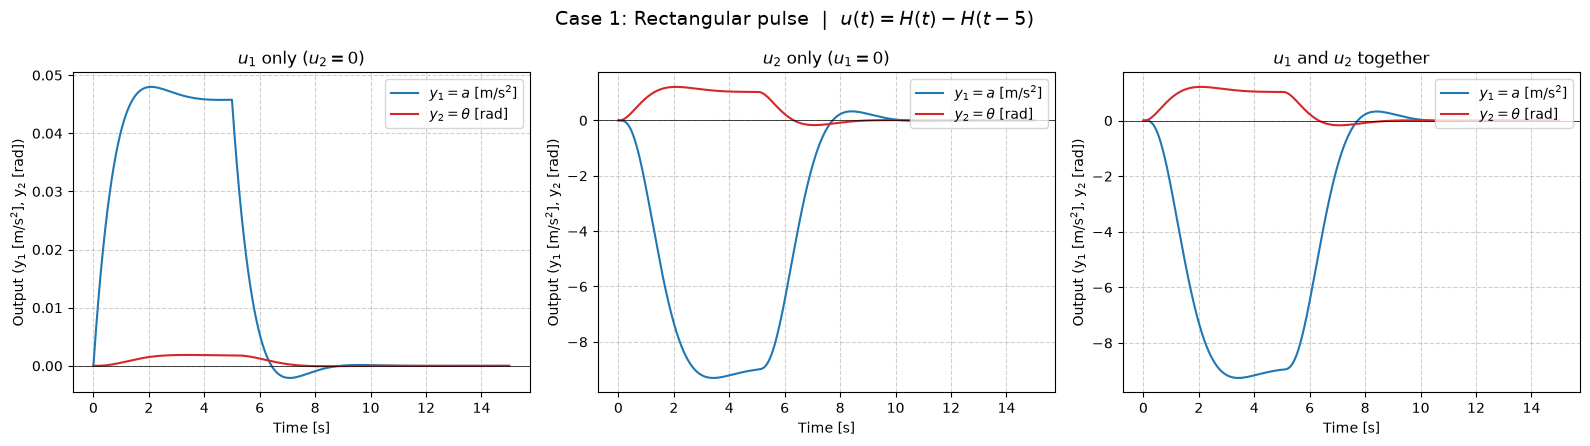

In [78]:
# Case 1: rectangular pulse u(t) = H(t) - H(t-5)  (unit input switched on at t=0 and off at t=5 s)
def u_pulse(t):
    # Heaviside step H(t) minus the same step delayed 5 s
    return np.heaviside(t, 1.0) - np.heaviside(t - 5.0, 1.0)

# Simulate 15 s so the response after the pulse ends (t > 5 s) is also visible
T1, y_pulse = simulate_input_cases(sys, u_pulse, T_max=15,
                                   title="Case 1: Rectangular pulse",
                                   u_label=r"$u(t)=H(t)-H(t-5)$")


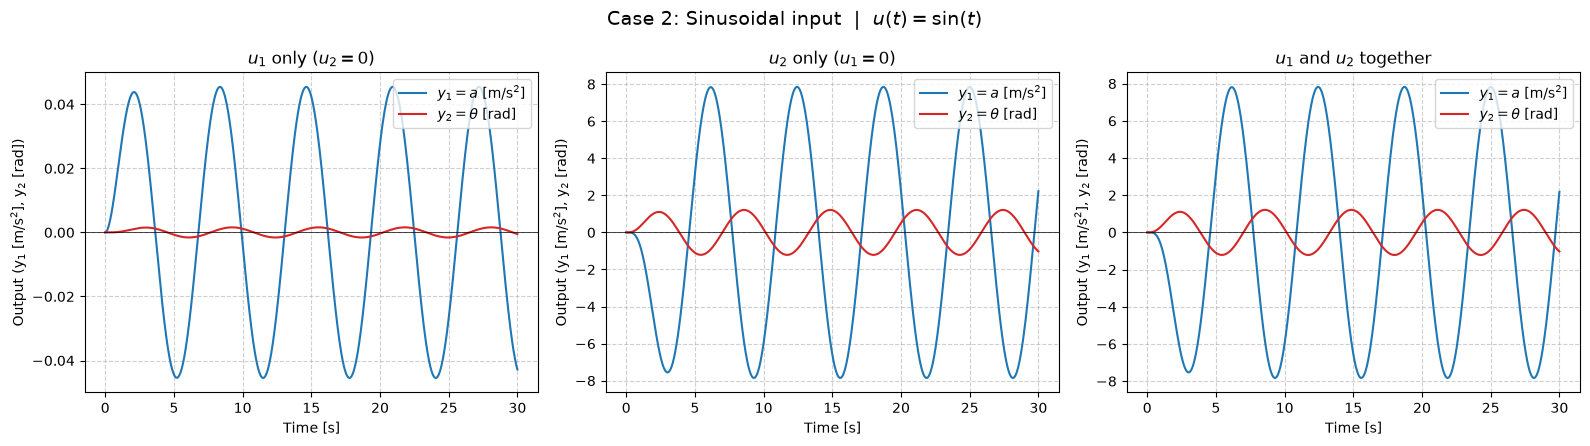

In [79]:
# Case 2: sinusoidal input u(t) = sin(t)  (omega = 1 rad/s)
def u_sine(t):
    return np.sin(t)

# Simulate 30 s (about 5 periods) so the transient dies out and the steady-state oscillation shows
T2, y_sine = simulate_input_cases(sys, u_sine, T_max=30,
                                  title="Case 2: Sinusoidal input",
                                  u_label=r"$u(t)=\sin(t)$")


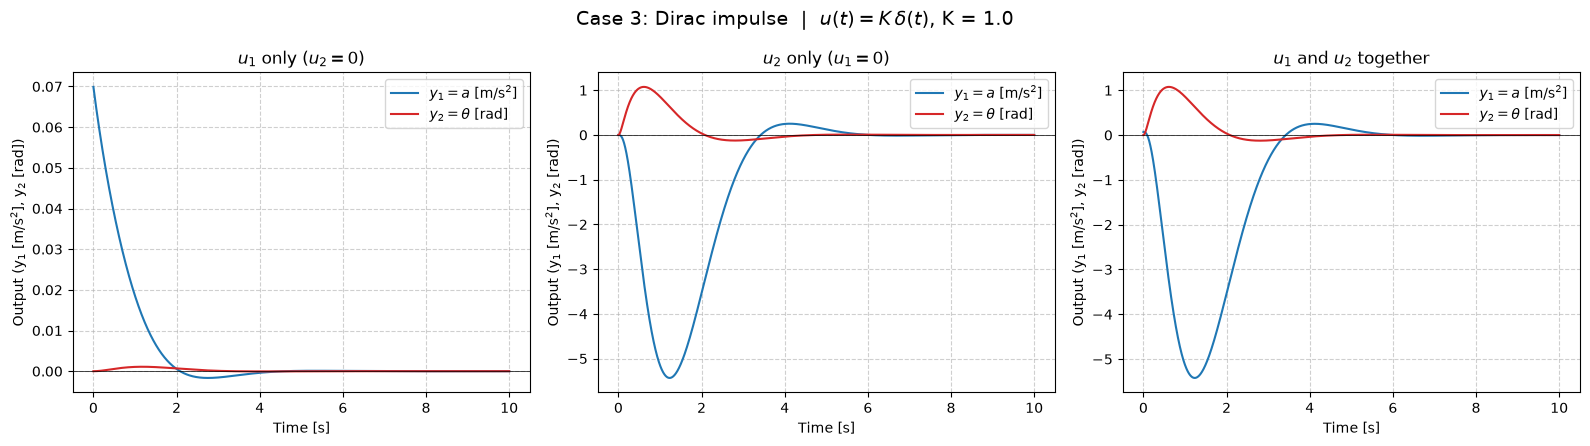

In [80]:
# Case 3: Dirac impulse u(t) = K * delta(t)  (wind gust / sudden hit)
K_impulse = 1.0   # impulse strength K (change to scale the gust)

# Impulse response is computed with signal.impulse inside the helper (impulse_K activates that branch)
# 10 s is enough to see the response decay back to zero (all poles are in the left half-plane)
T3, y_impulse = simulate_input_cases(sys, None, T_max=10,
                                     title="Case 3: Dirac impulse",
                                     u_label=r"$u(t)=K\,\delta(t)$, K = " + str(K_impulse),
                                     impulse_K=K_impulse)
